# Data audit and preprocessing verification

Steps 1-6 define the problem, verify local setup, preserve the snapshot, save partitions, explore development-train, and verify training-fitted preprocessing. No project classifier has been trained.

See the [project report](../reports/PROJECT_REPORT.md), [data boundaries](../reports/DATA_BOUNDARIES.md), [EDA report](../reports/EDA_REPORT.md), [preprocessing report](../reports/PREPROCESSING.md), and [local setup](../LOCAL_SETUP.md).

## Problem definition

Predict `health_class` (`healthy`, `moderate_stress`, `high_stress`) from eight environmental measurements and three context categories. The primary model is regularized multiclass logistic regression, fitted by numerical optimization of cross-entropy plus an L2 penalty. Macro F1 is the primary selection metric. This is an educational synthetic-data exercise, not validated real-plant diagnosis.

The [full problem definition](../reports/PROJECT_REPORT.md#problem-definition--step-1) fixes the evaluation and tie rules before modeling.

In [1]:
from pathlib import Path
import importlib.metadata
import json
import platform
import subprocess
import sys
from datetime import datetime, timezone

# Support launching from either the repository root or notebooks directory.
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "src/config.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import RANDOM_SEED, SPLIT_SEED, MODEL_SEED, BOOTSTRAP_SEED

# Imports verify the scientific and notebook packages actually load together.
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import ipykernel
import jupyterlab

PACKAGES = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib",
            "seaborn", "jupyterlab", "ipykernel", "joblib"]
metadata = {
    "captured_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "executable": sys.executable,
    "platform": platform.platform(),
    "packages": {name: importlib.metadata.version(name) for name in PACKAGES},
    "seeds": {"split": SPLIT_SEED, "model": MODEL_SEED, "bootstrap": BOOTSTRAP_SEED},
    "compute": "CPU; optional JAX/Optax deferred",
    "status": "environment_verified; no model trained",
}
print(json.dumps(metadata, indent=2))
rng = np.random.default_rng(RANDOM_SEED)
print("Seeded NumPy example:", rng.integers(0, 100, size=5).tolist())
(ROOT / "reports/environment.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
(ROOT / "reports/environment.freeze.txt").write_text(freeze, encoding="utf-8")


{
  "captured_at_utc": "2026-11-22T02:15:16.961376+00:00",
  "python": "3.11.5",
  "executable": "C:\\Users\\jettw\\Documents\\Fall2026\\ML\\EcoSystem\\.venv\\Scripts\\python.exe",
  "platform": "Windows-10-10.0.26200-SP0",
  "packages": {
    "numpy": "2.4.6",
    "pandas": "3.1.1",
    "scipy": "1.17.1",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "seaborn": "0.13.2",
    "jupyterlab": "4.6.6",
    "ipykernel": "7.4.0",
    "joblib": "1.6.0"
  },
  "seeds": {
    "split": 42,
    "model": 42,
    "bootstrap": 42
  },
  "compute": "CPU; optional JAX/Optax deferred",
  "status": "environment_verified; no model trained"
}

Seeded NumPy example:

[8, 77, 65, 43, 43]

1985

## Preserved local snapshot

Source CSV/card bytes are hashed and versioned in [the provenance record](../reports/dataset_snapshot.json). This cell verifies integrity and loads training data without network access; it does not explore labels or feature distributions.

In [2]:
from src.data import load_split, verify_snapshot

snapshot = verify_snapshot()
training_data = load_split("train")
print("Dataset:", snapshot["dataset_id"])
print("Revision:", snapshot["revision"])
print("Downloaded (UTC):", snapshot["downloaded_at_utc"])
print("Train shape:", training_data.shape)
print("Test rows (manifest structural count only):", snapshot["files"]["test.csv"]["rows"])
print("License:", snapshot["license_status"])
print("Raw-file hashes verified. No label counts or feature distributions inspected.")


Dataset:

soumikmahato/plant-health-points-synthetic

Revision:

d7b9f23bce2f5cf02c3be85c38506cf386d9d0b2

Downloaded (UTC):

2026-11-22T01:48:55.880101+00:00

... (3 outputs left out)

500

License:

Not declared in dataset card or repository files at this revision; no reuse license inferred.

Raw-file hashes verified. No label counts or feature distributions inspected.

## Saved development partitions and schema

The split was generated by the explicit `python -m src.splits` command. This cell reloads saved development partitions and audit metadata; it does not reload the raw test table. Numeric ranges and vocabularies shown below come from development-train only. Units and valid-value uncertainties are documented in [the boundary report](../reports/DATA_BOUNDARIES.md).

In [3]:
from src.schema import FEATURES, CLASSES, EXCLUDED_COLUMNS, features_target_ids
from src.splits import load_development_split

boundaries = json.loads((ROOT / "reports/data_boundaries.json").read_text(encoding="utf-8"))
development_train = load_development_split("development_train")
validation = load_development_split("validation")
X_train, y_train, train_ids = features_target_ids(development_train)
X_validation, y_validation, validation_ids = features_target_ids(validation)
assert not set(train_ids) & set(validation_ids)
assert set(X_train.columns) == set(FEATURES)
assert not set(EXCLUDED_COLUMNS) & set(X_train.columns)
assert set(y_train.unique()) == set(CLASSES) == set(y_validation.unique())
print("Saved partition counts:", boundaries["counts"])
print("Predictor shapes:", X_train.shape, X_validation.shape)
print("Excluded from predictors:", list(EXCLUDED_COLUMNS))
print("Exact duplicate/overlap audit:", boundaries["integrity"])
print("No transformations fitted; test labels/distributions remain reserved.")
display(pd.DataFrame(boundaries["schema"]))


Saved partition counts:

{'development_train': 1600, 'test': 500, 'validation': 400}

Predictor shapes:

(1600, 11)

(400, 11)

Excluded from predictors:

['record_id', 'health_score', 'health_class']

Exact duplicate/overlap audit:

{'train_missing_ids': 0, 'test_missing_ids': 0, 'train_duplicate_ids': 0, 'test_duplicate_ids': 0, 'train_duplicate_predictor_rows': 0, 'test_duplicate_predictor_rows': 0, 'train_conflicting_predictor_groups': 0, 'cross_split_id_overlap': 0, 'cross_split_predictor_overlap': 0}

No transformations fitted; test labels/distributions remain reserved.

,column,loaded_dtype,role,development_train_missing,observed_categories,category_count,observed_range
0,record_id,string,excluded,0,NaN,NaN,NaN
1,plant_type,string,categorical_predictor,0,"[aloe_vera, basil, lettuce, mint, pothos, rose...",8.0,NaN
2,habitat,string,categorical_predictor,0,"[arid_garden, garden, greenhouse, hydroponic, ...",6.0,NaN
3,season,string,categorical_predictor,0,"[autumn, monsoon, spring, summer, winter]",5.0,NaN
4,air_humidity_pct,float64,numeric_predictor,0,NaN,NaN,"[25.0, 93.9]"
5,soil_humidity_pct,float64,numeric_predictor,0,NaN,NaN,"[8.1, 90.0]"
6,ethylene_ppm,float64,numeric_predictor,0,NaN,NaN,"[0.001, 2.496]"
7,co2_ppm,float64,numeric_predictor,0,NaN,NaN,"[330.5, 1249.7]"
8,o2_ppm,float64,numeric_predictor,0,NaN,NaN,"[18.2, 21.5]"
9,ldr_on_plant,float64,numeric_predictor,0,NaN,NaN,"[30.0, 1023.0]"


## Development-training exploration ? Step 5

The EDA module loads only the saved 1,600 development-training records. Validation/test data are excluded from descriptive statistics, plots, and score-label auditing; no transformations are fitted. The majority-class accuracy below is an in-sample descriptive reference, not validation or test performance.

In [4]:
from src.eda import run_eda
eda = run_eda()
print("Analysis scope:", eda["scope"], "| Rows:", eda["rows"])
print("Majority class:", eda["majority_class"])
print("Development-training majority accuracy:", f"{eda['majority_accuracy']:.2%}")
display(pd.DataFrame({"count": eda["class_counts"], "proportion": eda["class_proportions"]}))
print("IQR flags (overall development-train):", eda["iqr_flag_counts"])
print("Documented-bound violations:", eda["documented_bound_violations"])
print("Corrections:", eda["corrections"], "| Rows removed:", eda["rows_removed"])
print("Score/class ranges (excluded label audit only):", eda["score_ranges_by_class"])
print("Score values with multiple labels:", eda["score_values_with_multiple_classes"])
print("Post-hoc score-threshold agreement:", eda["score_threshold_agreement"])
print("No imputation, scaling, encoding, feature selection, or model fitting has occurred.")


Analysis scope:

development_train only

| Rows:

1600

Majority class:

moderate_stress

... (14 outputs left out)

0

Post-hoc score-threshold agreement:

1.0

No imputation, scaling, encoding, feature selection, or model fitting has occurred.

## Figures and interpretations

Every figure below uses development-train only. Gas-reading units remain uncertain, and score plots are solely for leakage diagnosis.

### Class balance

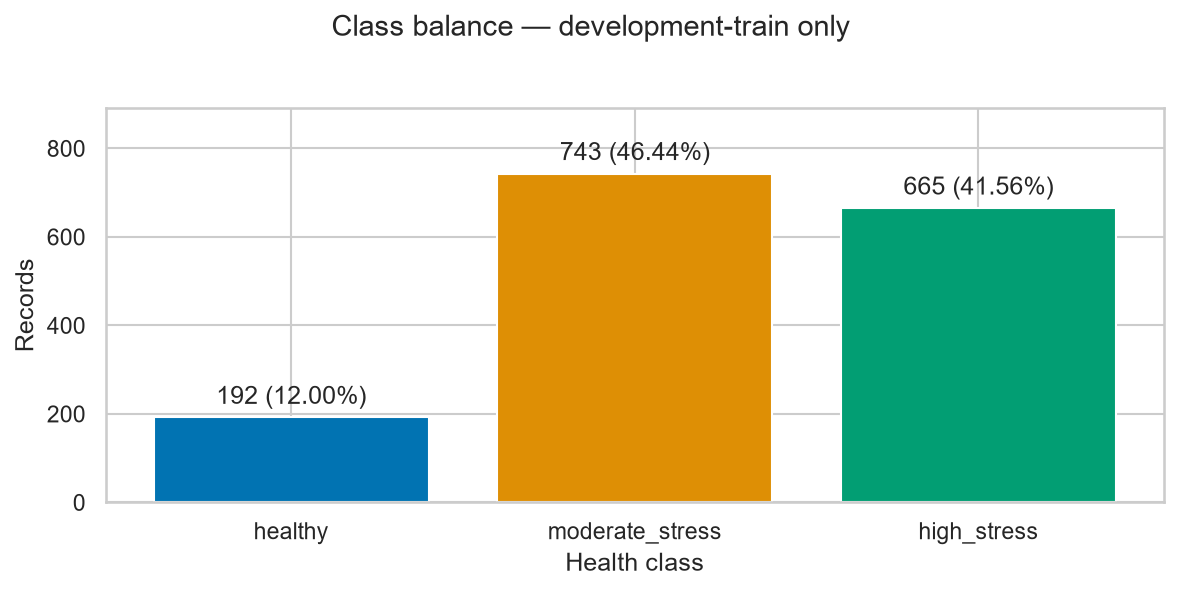

Moderate stress is the majority class (743 of 1600; 46.44%), while healthy has only 192 records (12.00%). A constant-majority prediction therefore gives 46.44% development-training accuracy; macro F1 and per-class recall are needed to expose minority-class failures.

### Numeric sensor distributions

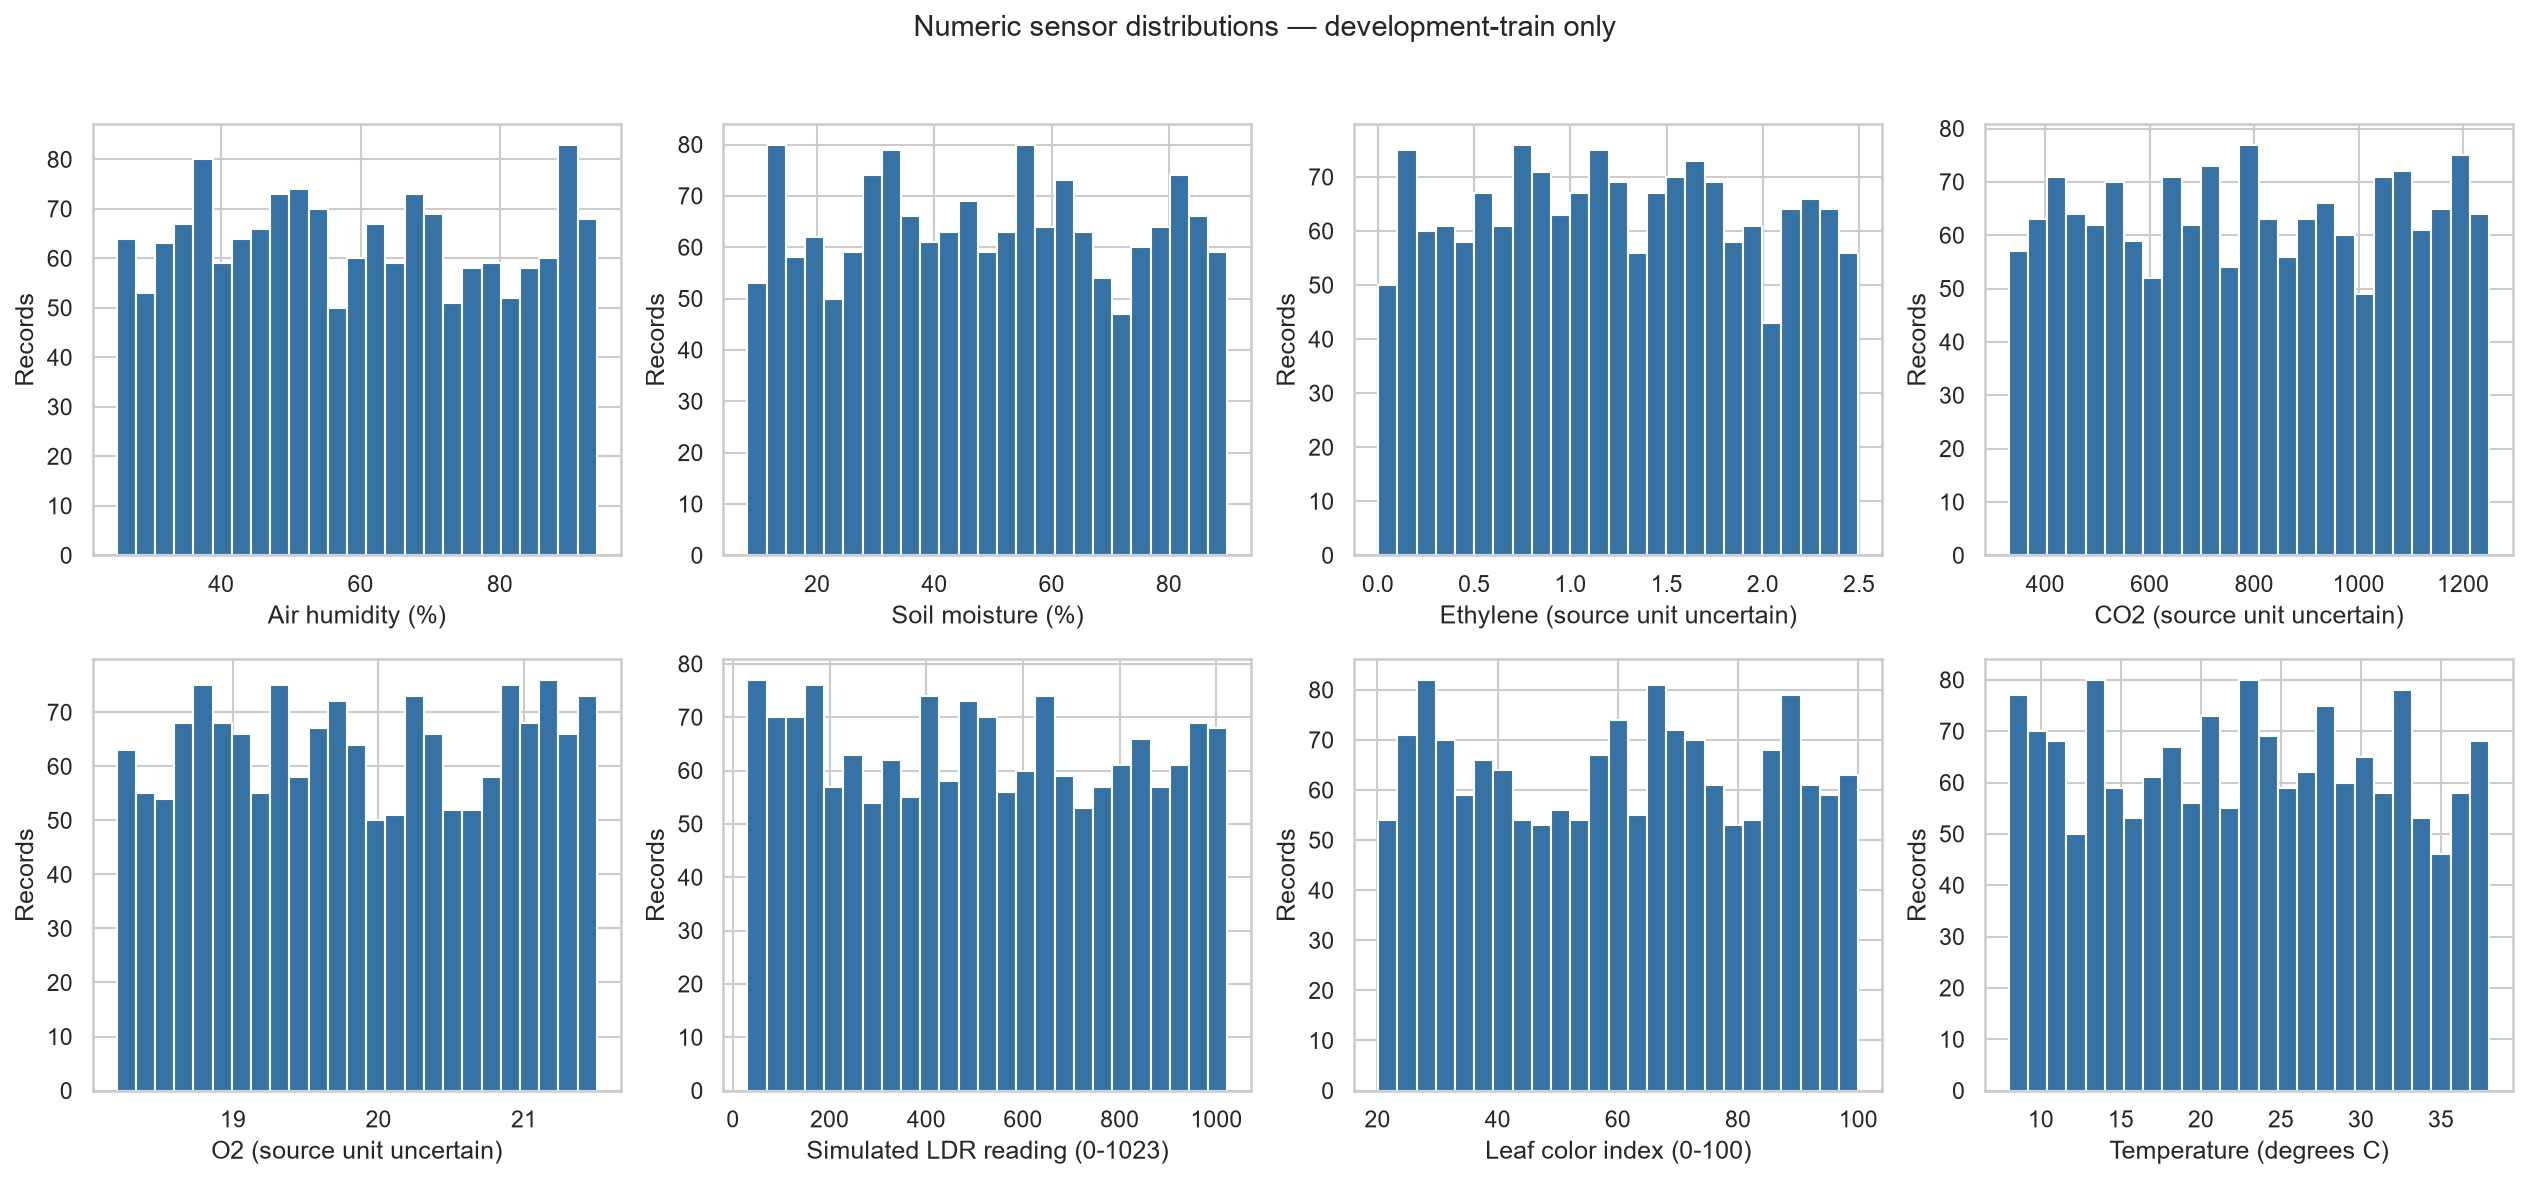

The broad, fairly flat sensor distributions are consistent with simulated ranges, rather than evidence of measured natural variability. Their scales differ substantially, motivating training-fitted standardization for linear models; uncertain gas units remain unconverted.

### Missing values

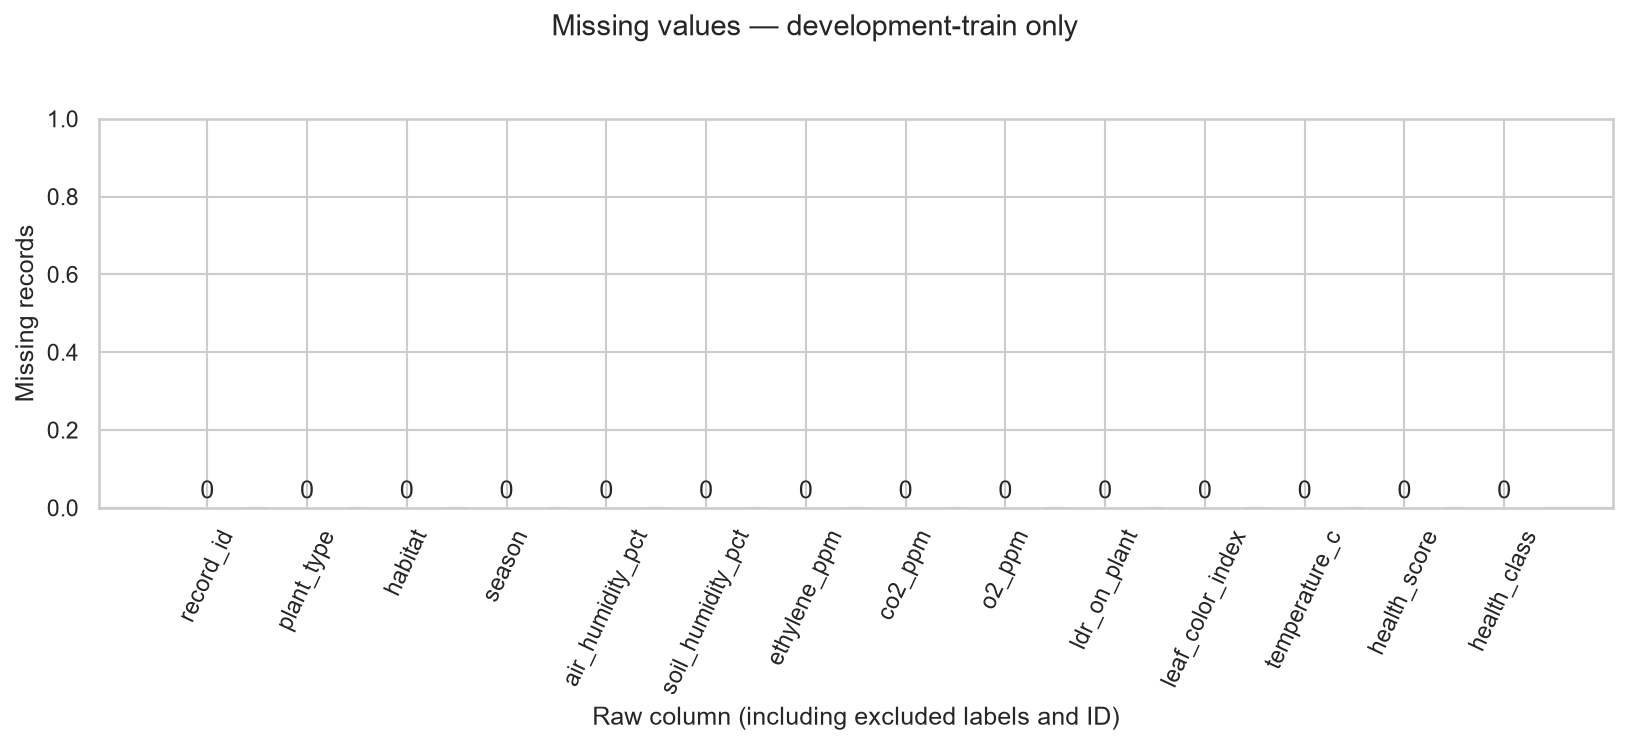

All 14 development-training fields have zero missing values. No imputation or row deletion is needed for this snapshot, although a training-fitted imputer remains planned for the reusable pipeline.

### Categorical frequencies

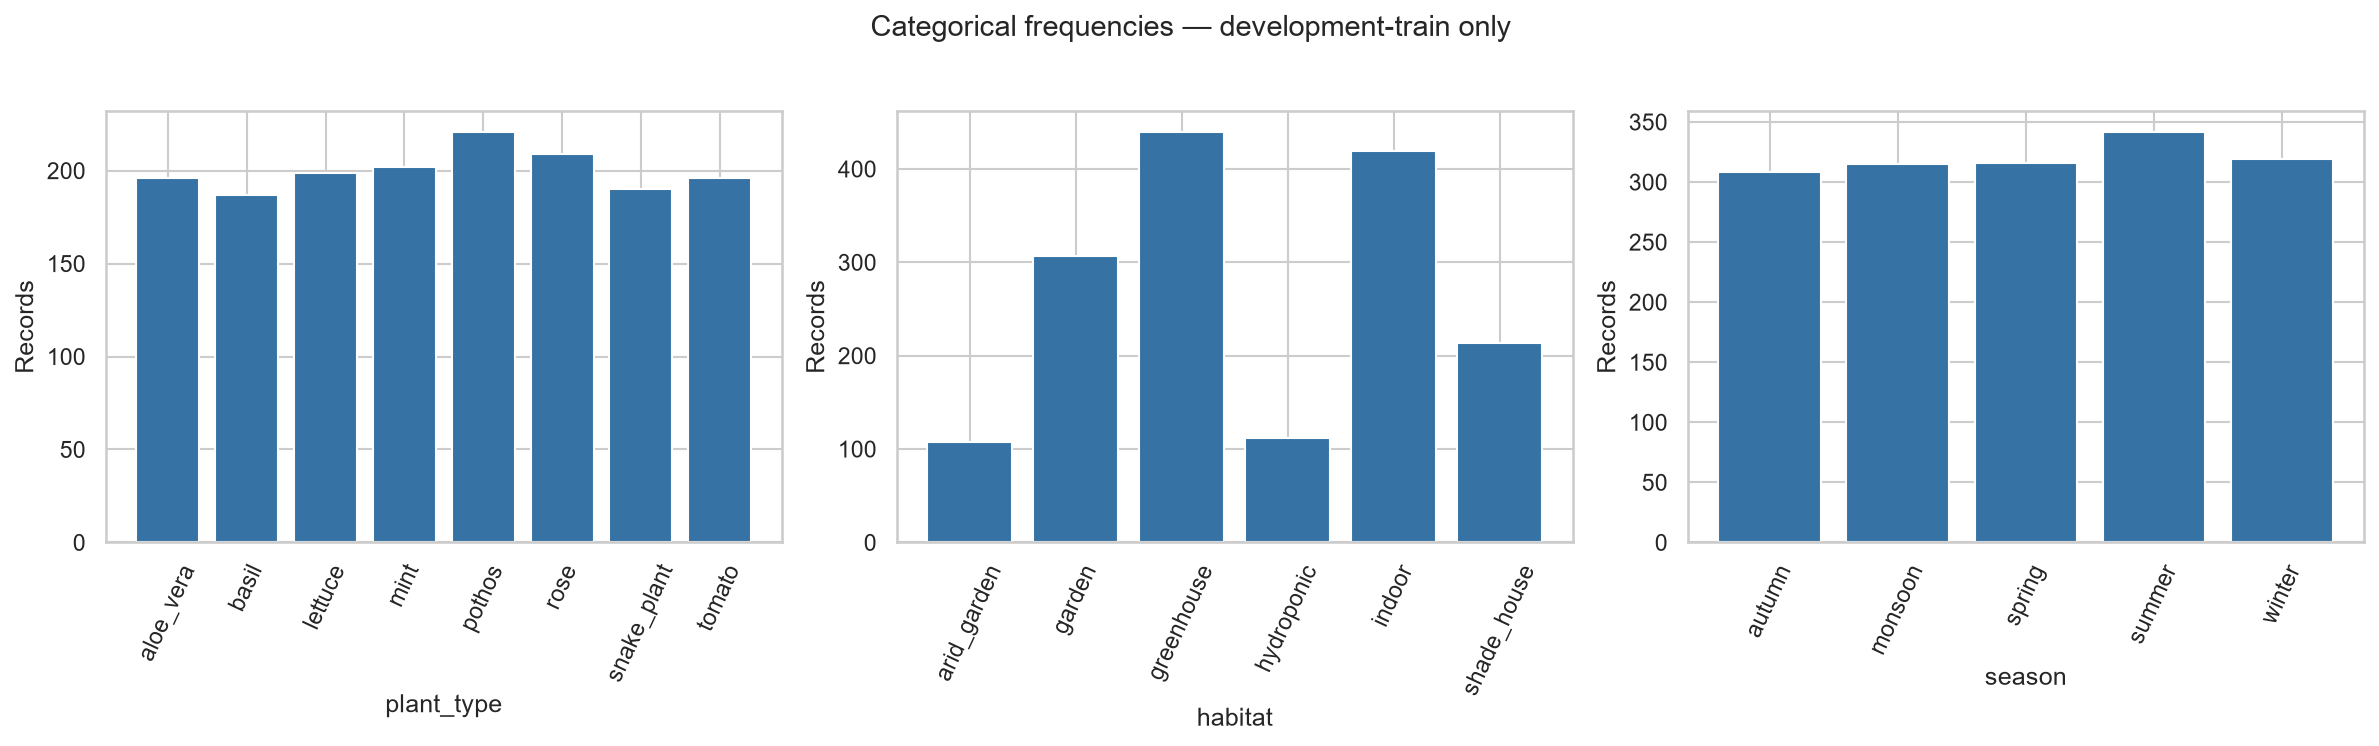

Plant types and seasons are relatively evenly represented, whereas habitats are uneven: greenhouse and indoor are common and arid_garden/hydroponic are much smaller groups. These counts describe coverage in synthetic development data, not real-world prevalence.

### Sensor distributions by class

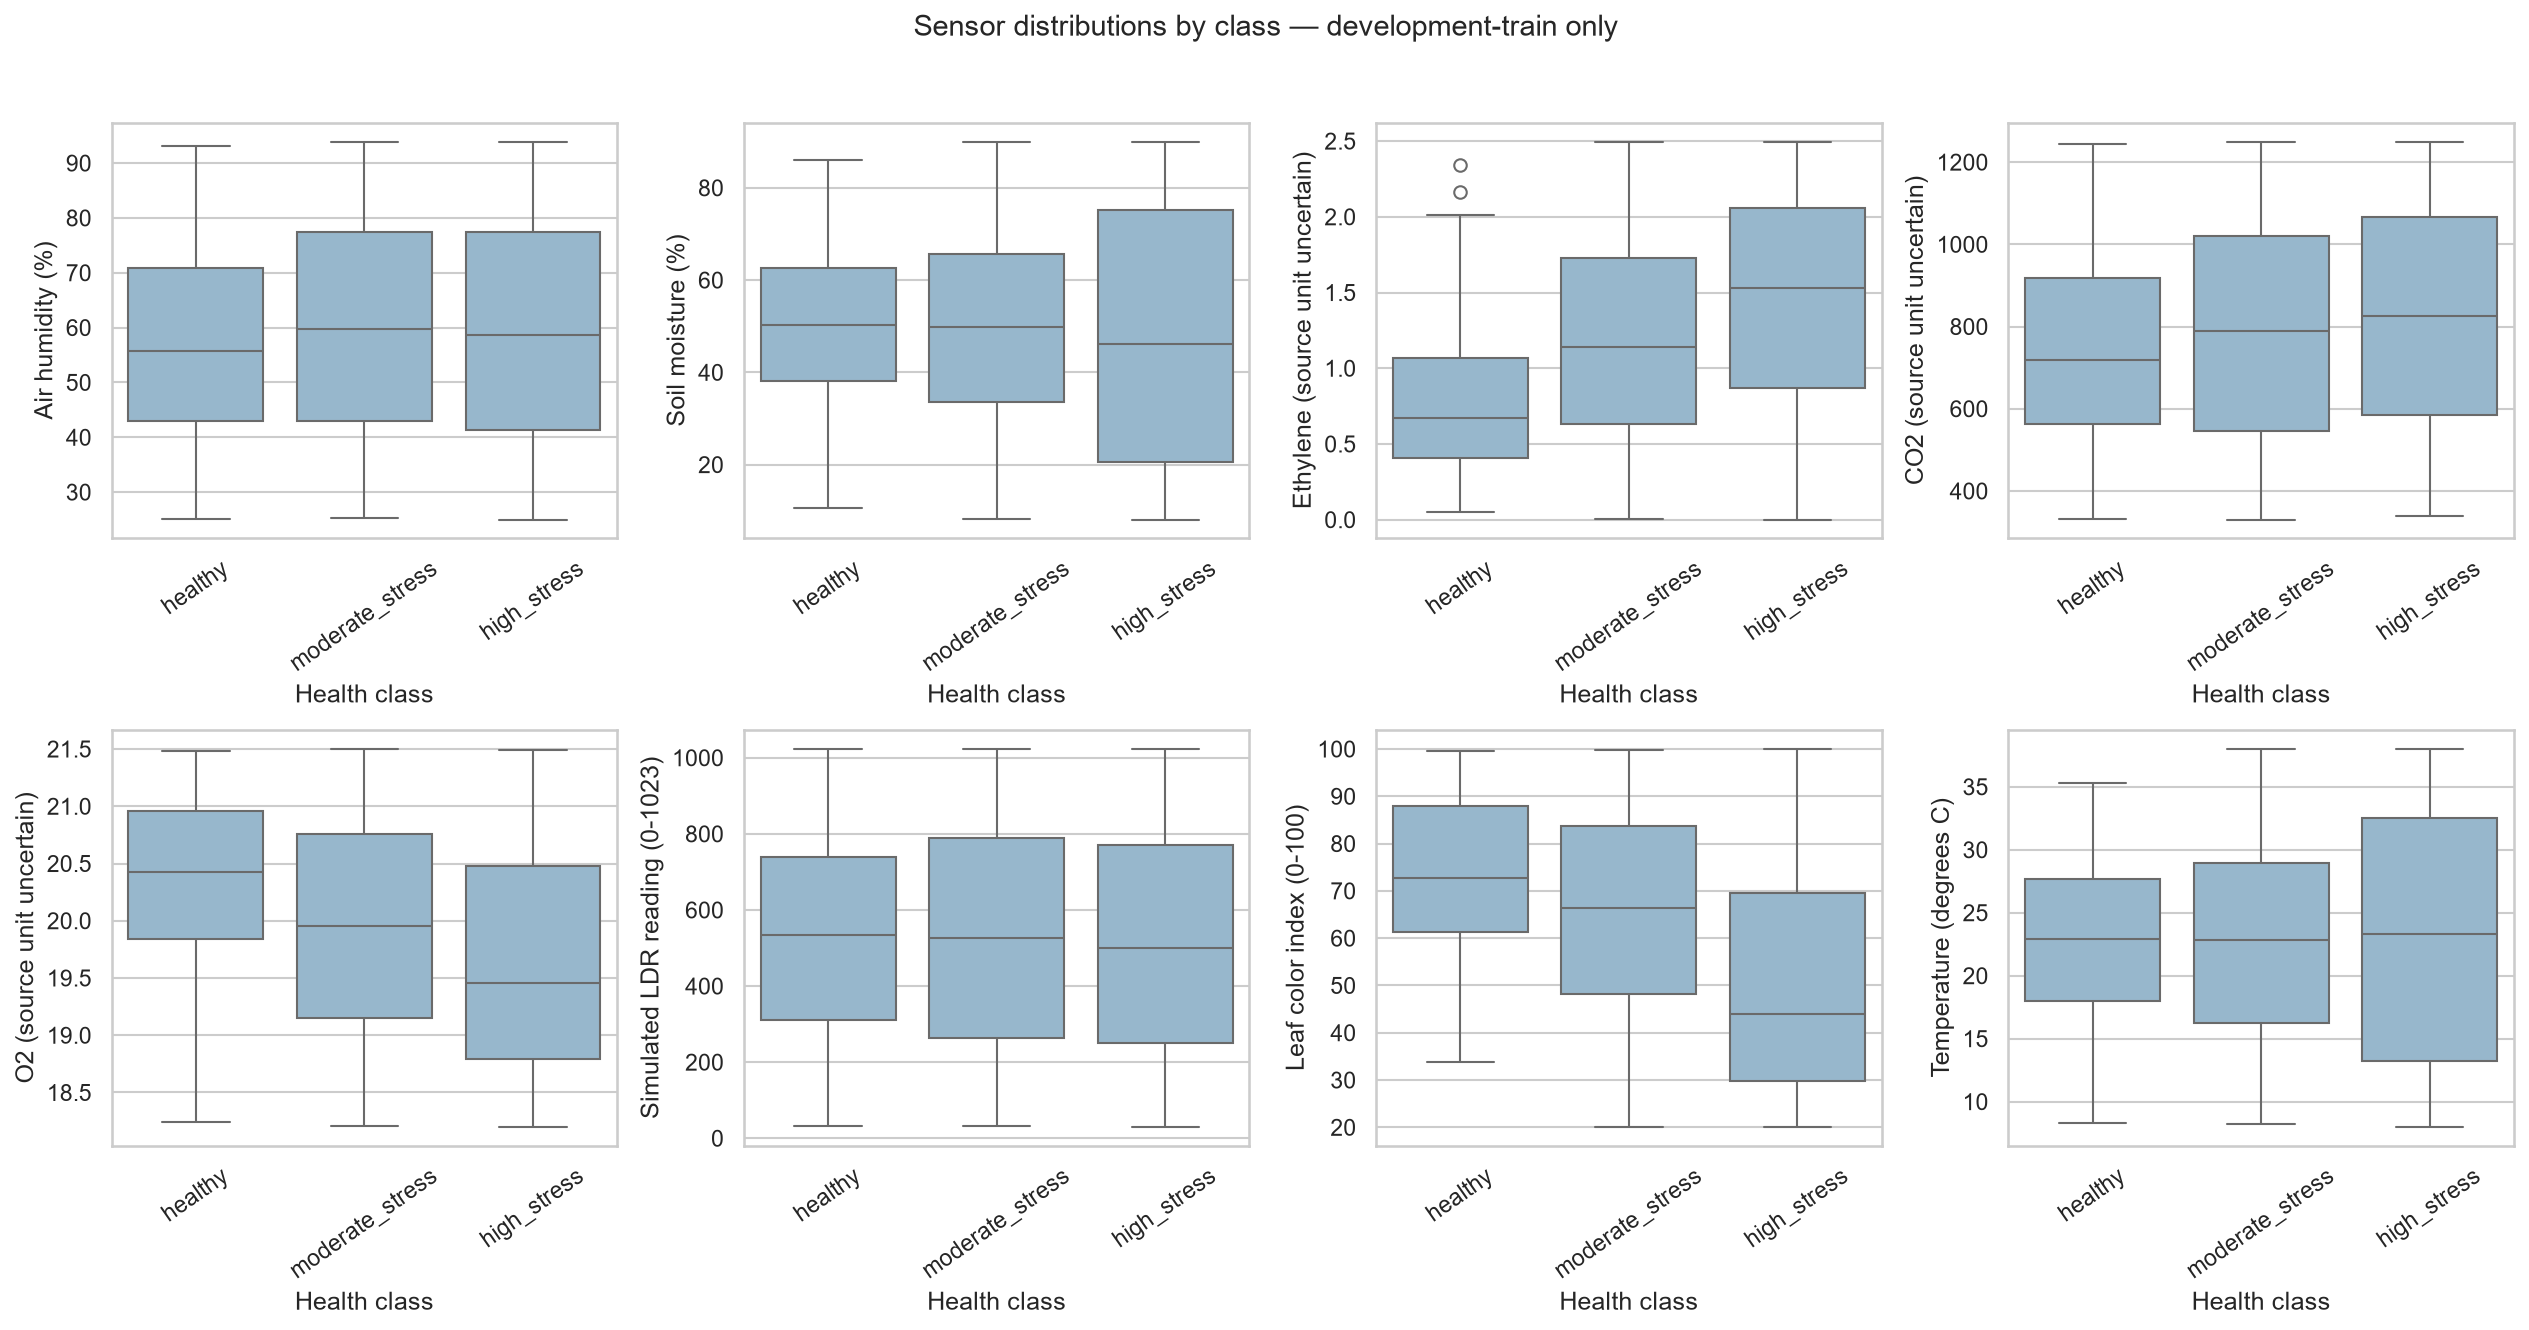

Leaf color, ethylene, and oxygen show visible class shifts, but distributions overlap and the synthetic scoring recipe can create these associations without establishing biological causation. Boxplot fliers use within-class IQR fences, which differ from the overall-development IQR screen reported in the range audit; no fliers were removed.

### Class proportions by context

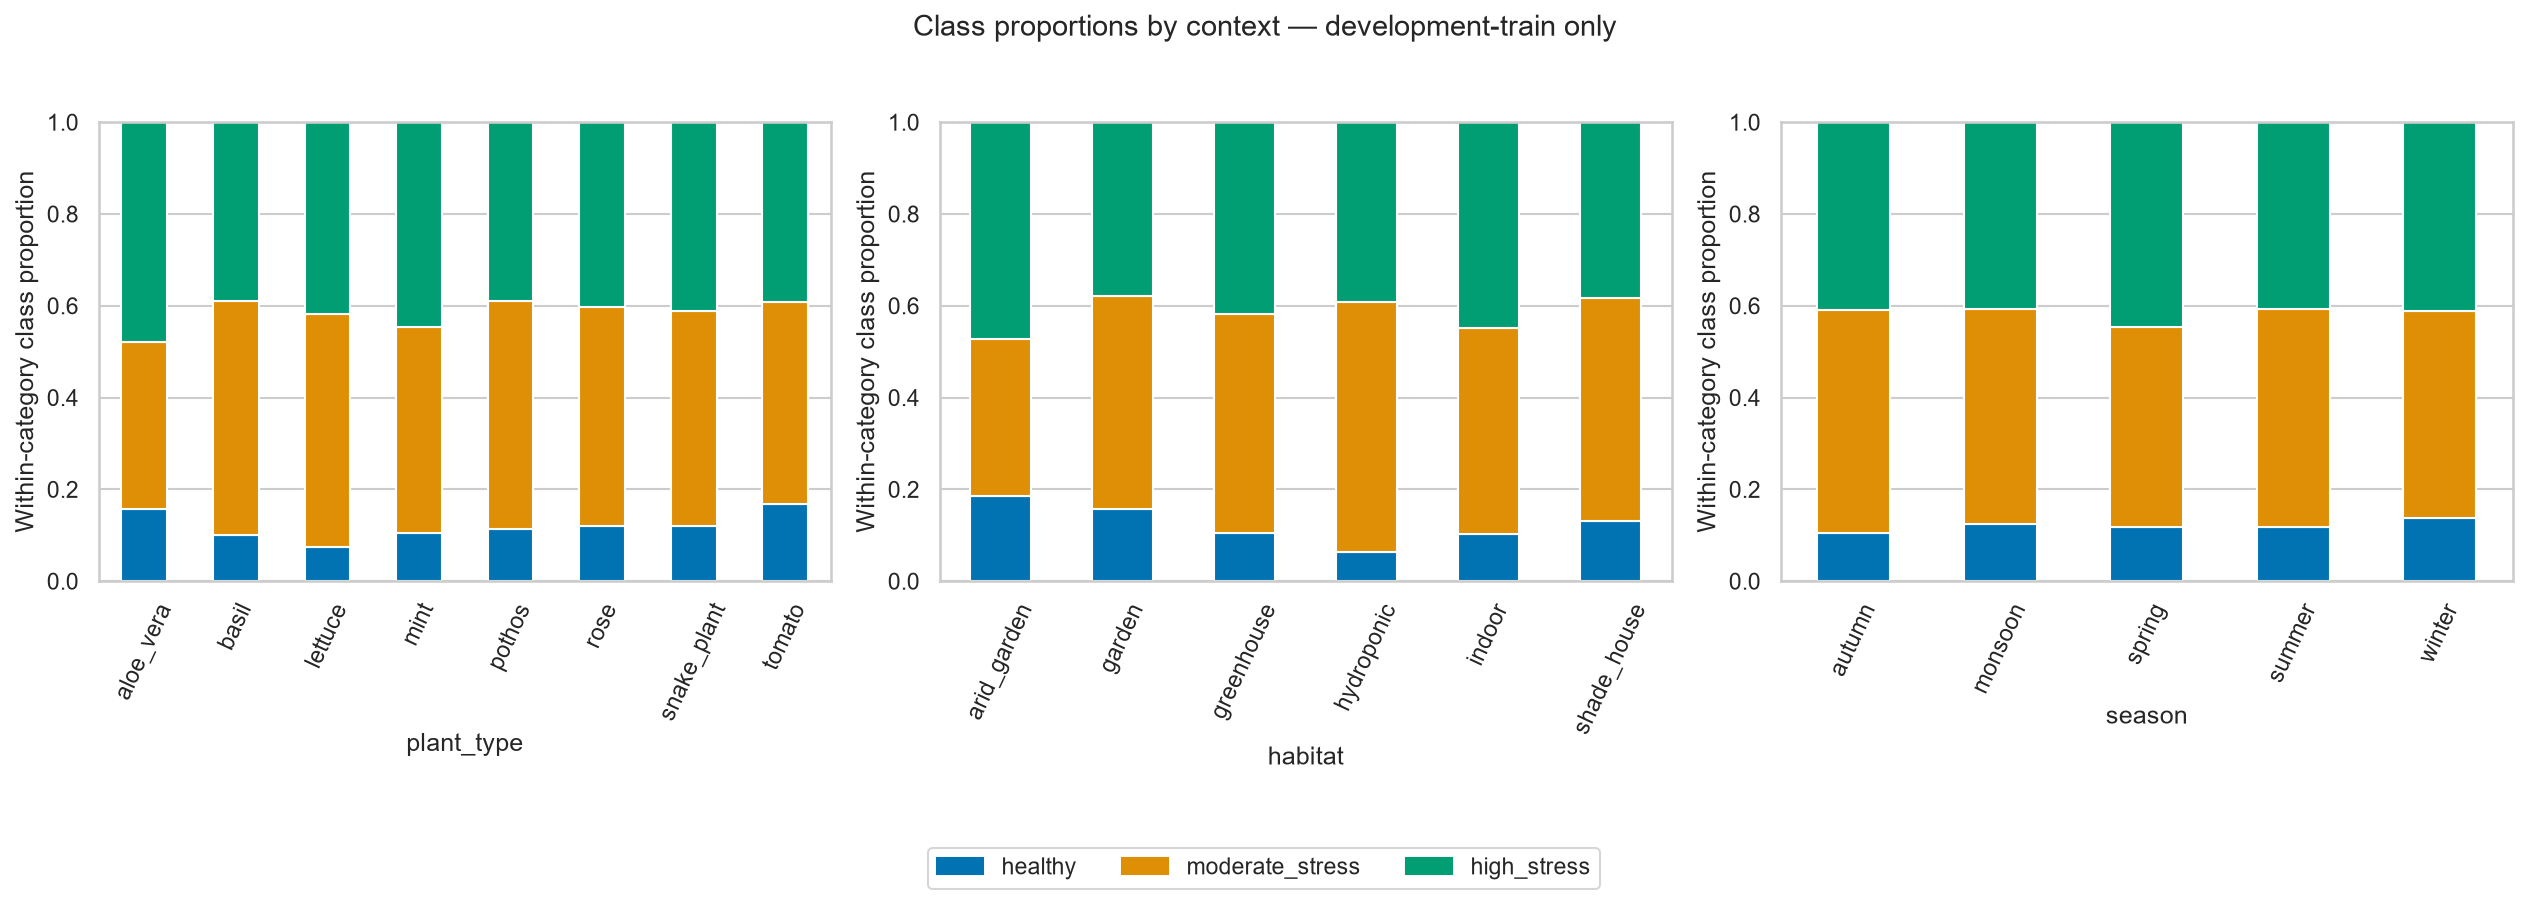

Class proportions vary across context categories, so categorical inputs may encode part of the synthetic label-generation process. Each bar is normalized within its category; inspect the preceding frequency plot before interpreting differences in smaller groups.

### Sensor correlation matrix

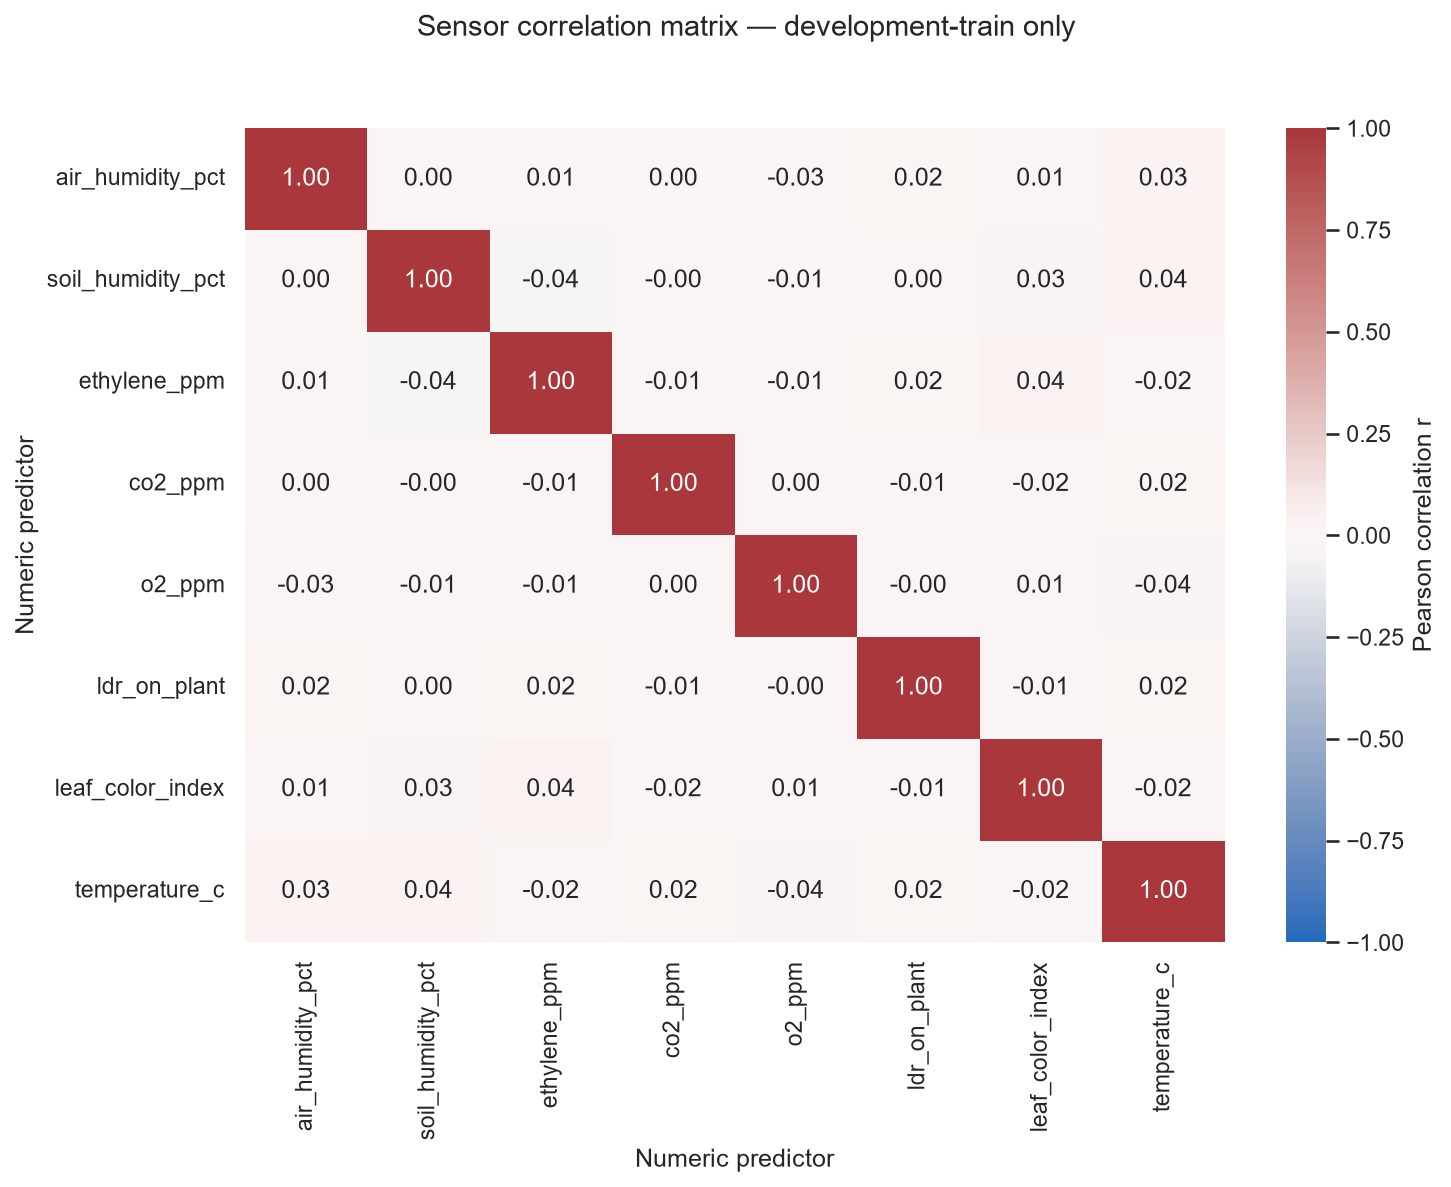

The largest absolute off-diagonal Pearson correlation is only 0.044 (soil_humidity_pct versus ethylene_ppm); no strong linear sensor redundancy appears. Near-zero correlation does not prove independence: nonlinear dependence may remain, and correlated predictors, if present, can destabilize individual coefficients even when predictions are stable.

### Selected sensor pairs

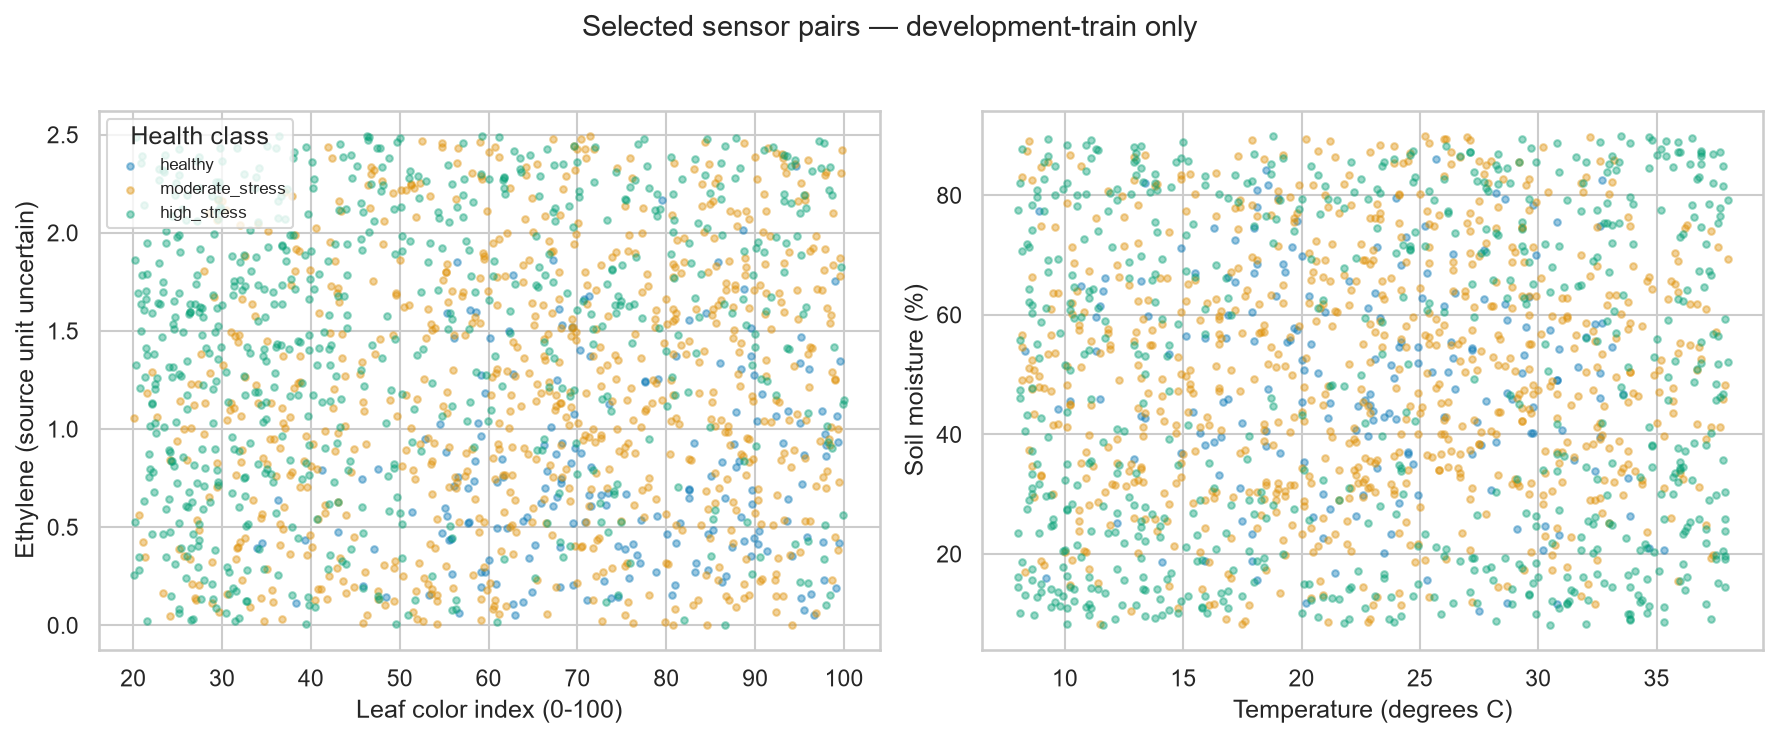

The leaf-color/ethylene panel shows class structure with substantial overlap; temperature/soil-moisture does not show an obvious single linear class boundary. These are descriptive views of two selected pairs, not evidence that remaining features are unimportant or that any classifier will generalize.

### Excluded score and label-generation audit

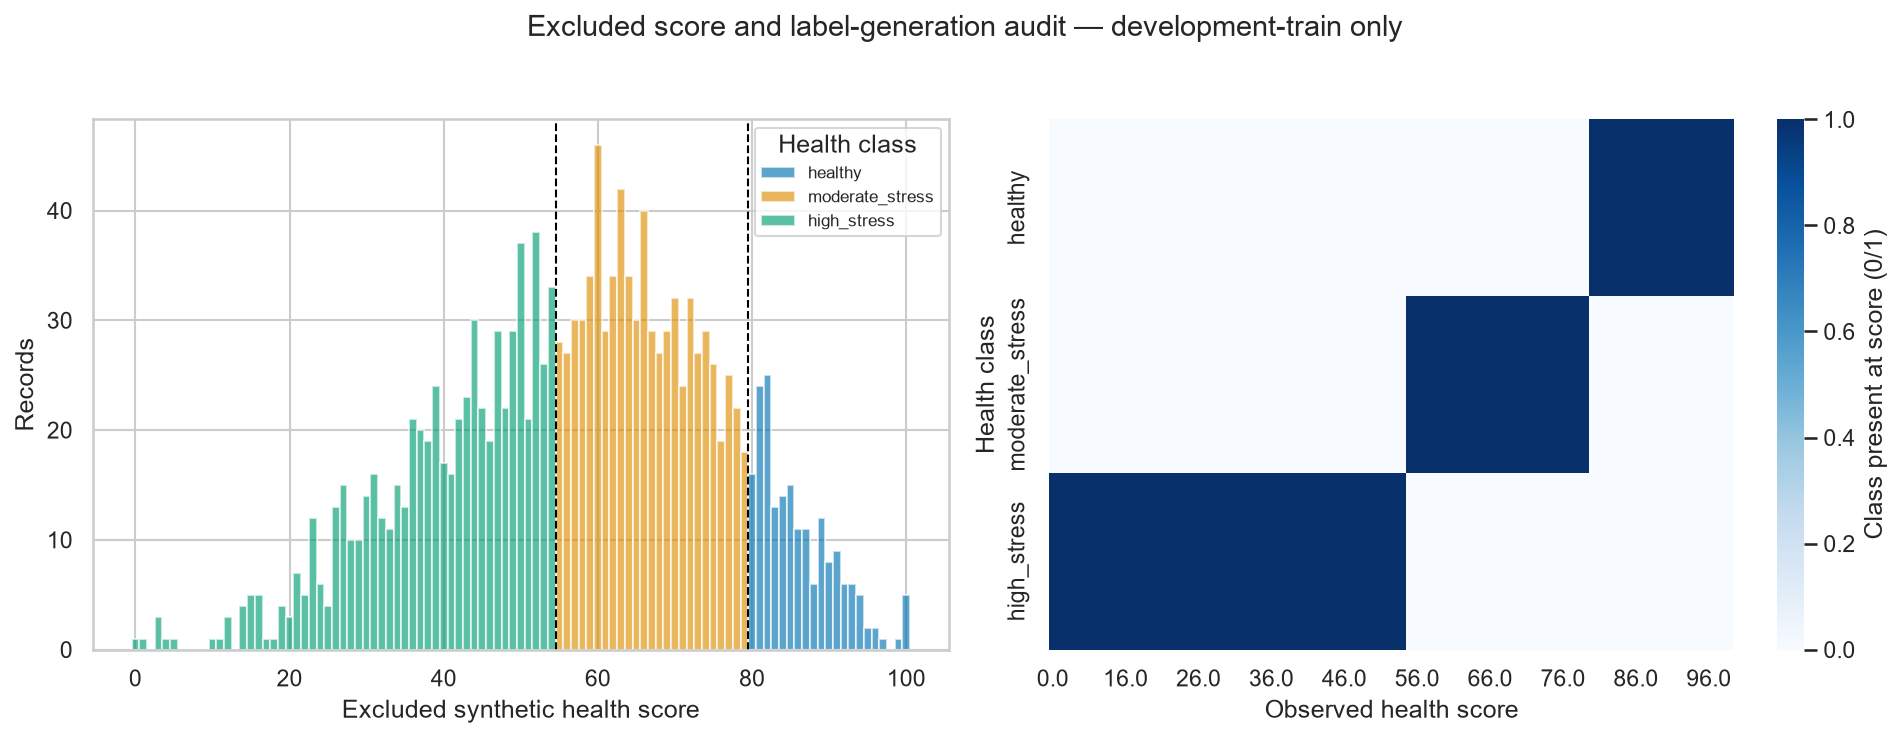

In these development-training records, high stress occupies scores 0-54, moderate stress 55-79, and healthy 80-100; no observed score maps to multiple classes. Thresholds at 55 and 80 reproduce all observed labels, providing post-hoc leakage evidence rather than an independently evaluated model; health_score remains excluded from all predictors.

In [5]:
from IPython.display import Image, Markdown, display
for figure in eda["figures"]:
    display(Markdown("### " + figure["title"]))
    display(Image(filename=str(ROOT / "reports" / figure["file"])))
    display(Markdown(figure["interpretation"]))


## Conclusions and next step

Healthy records are the minority class, making macro F1 and per-class recall essential. Weak pairwise linear correlations do not prove independence; nonlinear sensor and context relationships can remain. The synthetic score completely separates the observed class ranges and stays excluded alongside the target and record ID. No values were corrected or removed.

The following section verifies imputation, standardization, and encoding fitted on development-train only.

## Reusable preprocessing ? Step 6

The verification function loads the saved development-training/validation partitions, fits only on development-train, and transforms validation without refitting. It checks named outputs, missing values, unseen categories, a new row, unchanged learned state, and artifact reloading. No project classifier or test-data analysis is performed.

In [6]:
from src.pipeline import verify_preprocessing
preprocessing = verify_preprocessing()
print("Status:", preprocessing["status"])
print("Transformed train shape:", preprocessing["training_shape"])
print("Transformed validation shape:", preprocessing["validation_shape"])
print("Checks:", preprocessing["checks"])
print("Fixed probability-column mapping:", preprocessing["class_to_probability_column"])
display(pd.DataFrame({"position": range(len(preprocessing["feature_names"])), "feature": preprocessing["feature_names"]}))


Status:

preprocessing_verified; no project classifier fitted

Transformed train shape:

[1600, 27]

Transformed validation shape:

[400, 27]

Checks:

{'validation_did_not_refit': True, 'new_row': True, 'missing_values': True, 'unseen_categories': True, 'finite_consistent_width': True, 'excluded_fields_absent': True, 'serialization_roundtrip': True}

Fixed probability-column mapping:

{'healthy': 0, 'moderate_stress': 1, 'high_stress': 2}

,position,feature
0,0,numeric__air_humidity_pct
1,1,numeric__soil_humidity_pct
2,2,numeric__ethylene_ppm
3,3,numeric__co2_ppm
4,4,numeric__o2_ppm
5,5,numeric__ldr_on_plant
6,6,numeric__leaf_color_index
7,7,numeric__temperature_c
8,8,categorical__plant_type_aloe_vera
9,9,categorical__plant_type_basil


The 27 outputs contain eight standardized numeric columns and 19 one-hot columns (8 plant types, 6 habitats, 5 seasons). Missing inputs are imputed using training statistics, unseen categories produce zero indicator blocks, and validation does not change learned state. The probability mapping will be applied by explicitly reordering future classifiers' probability arrays.

The saved preprocessor is an intermediate artifact. Pass the complete fresh model pipeline into cross-validation so every fold fits its own preprocessing. Step 7 will train and compare the majority baseline, logistic regression, and a shallow decision tree.